In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from uncertainties import ufloat, UFloat
from exp_phys_modules import exp_phys_misc as em
import handcalcs.render

### Measurements

In [5]:
# Measurements
mass = ufloat(0.5, 0.01)  # mass in kg
g = 9.81

# Create LateX table of measurements
df = pd.DataFrame([
    # headings
    {
        "{Quantity}": name,
        "{Reading}": val.n,
        "{Uncertainty}": val.s,
        "{units}": units
    }
    for name, val, units in [
        ("disk mass", m_disk, "kg"),
        ("bar mass", m_bar, "kg"),
        ("disk diameter", dia_disk, "m"),
        ("bar length", len_bar, "m"),
    ]
])
print(df.to_latex(index=False, position="H", caption="Experimental Parameters"))


NameError: name 'm_disk' is not defined

### Analysis of data

Short magnet dipole moment: 5.60061e-01 A*m^2
Long magnet dipole moment: 2.05414e+00 A*m^2


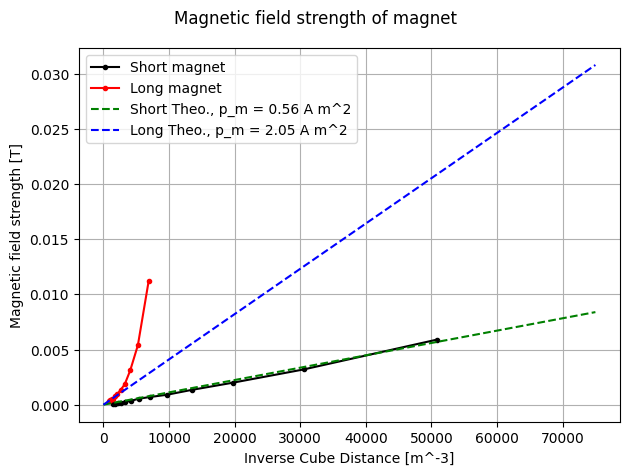

In [56]:
# Read data from Excel file
import numpy as np
import matplotlib.pyplot as plt
import polars as pl

MU0 = 1.25663706e-6
LENGTH_SHORT = 26.0e-3
LENGTH_LONG = 85.0e-3

df_short = pl.read_csv("data/short.csv", ).drop_nulls(subset=["Distance", "B_z [T]"])
df_long = pl.read_csv("data/long.csv", ).drop_nulls(subset=["Distance", "B_z [T]"])

# dist_short = df_short["Distance"].to_numpy()[1:]
dist_short = (df_short["Distance [mm]"].to_numpy()[1:] / 1000) - (LENGTH_SHORT / 2)
dist_inv_cube_short = dist_short ** (-3)
# dist_long = df_long["Distance"].to_numpy()
dist_long = (df_long["dist"].to_numpy() / 1000) - (LENGTH_LONG / 2)
dist_inv_cube_long = dist_long ** (-3)
Bz_short = df_short["B_z [T]"].to_numpy()[1:]
Bz_long = df_long["B_z [T]"].to_numpy()

const = MU0 / (2 * np.pi)
slope_short = (Bz_short[-1] - Bz_short[-4]) / (dist_inv_cube_short[-1] - dist_inv_cube_short[-4])
dipole_m_short = slope_short / const
slope_long = (Bz_long[-4] - Bz_long[-2]) / (
        dist_inv_cube_long[-4] - dist_inv_cube_long[-2]
)
dipole_m_long = slope_long / const

print(f"Short magnet dipole moment: {dipole_m_short:.5e} A*m^2")
print(f"Long magnet dipole moment: {dipole_m_long:.5e} A*m^2")

z_inv_cube = np.linspace(0, 75000, 1000)

Bz_short_theo = slope_short * z_inv_cube
Bz_long_theo = slope_long * z_inv_cube
# plot data
fig, ax = plt.subplots(1, 1)
fig.suptitle("Magnetic field strength of magnet")
ax.plot(dist_inv_cube_short, Bz_short, "k.-", label="Short magnet")
ax.plot(dist_inv_cube_long, Bz_long, "r.-", label="Long magnet")

ax.plot(z_inv_cube, Bz_short_theo, "g--", label=f"Short Theo., p_m = {dipole_m_short:.2f} A m^2")
ax.plot(z_inv_cube, Bz_long_theo, "b--", label=f"Long Theo., p_m = {dipole_m_long:.2f} A m^2")
ax.set_xlabel("Inverse Cube Distance [m^-3]")
ax.set_ylabel("Magnetic field strength [T]")

ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("figures/magnet_strength.png")
plt.show()



positive flux
fluxA = -1.117e-04,
fluxB = -1.081e-04,
fluxC = -1.133e-04,
fluxD = -1.104e-04,
flux total = -2.218e-05
negative flux
fluxA = 1.106e-04,
fluxB = 1.073e-04,
fluxC = 1.126e-04,
fluxD = 1.095e-04,
flux total = 2.200e-05


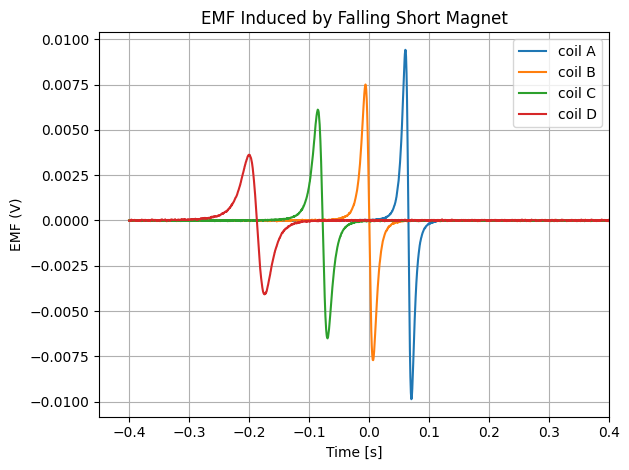

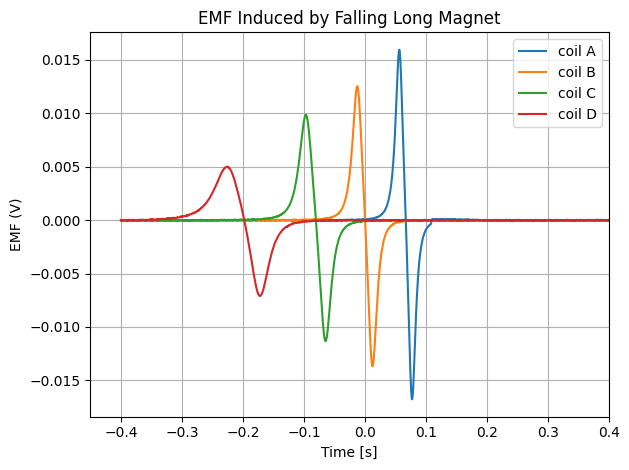

a = 9.4053
b = 3.5430
c = -0.0019


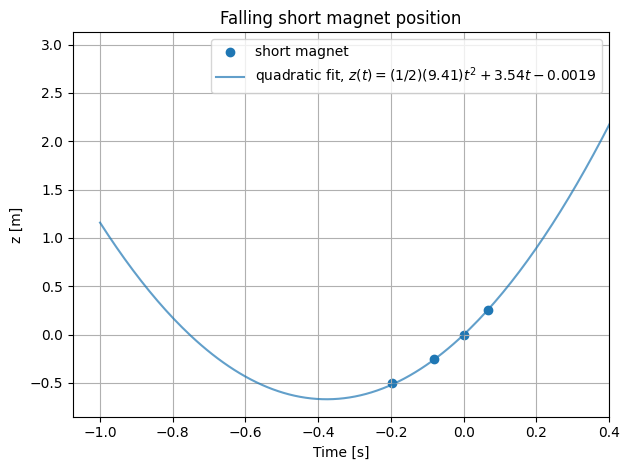

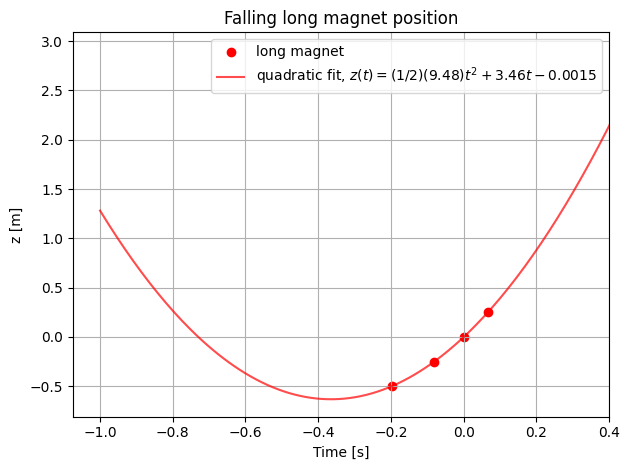

In [54]:
df_short = pl.read_csv("data/short.csv", )
df_long = pl.read_csv("data/long.csv", )
gain = 300
t_short = df_short["Time (s)"].to_numpy()
VA_short = df_short["Potential A (V)"].to_numpy() / gain
VB_short = df_short["Potential B (V)"].to_numpy() / gain
VC_short = df_short["Potential C (V)"].to_numpy() / gain
VD_short = df_short["Potential D (V)"].to_numpy() / gain

t_long = df_long["Time (s)"].to_numpy()
VA_long = df_long["Potential A (V)"].to_numpy() / gain
VB_long = df_long["Potential B (V)"].to_numpy() / gain
VC_long = df_long["Potential C (V)"].to_numpy() / gain
VD_long = df_long["Potential D (V)"].to_numpy() / gain


# integrate using riemann sum
def riemann_sum(f: np.ndarray, lower: float, upper: float, x: np.ndarray) -> float:
    """
    Returns Riemann sum - discrete data.
    """

    if len(f) != len(x):
        raise ValueError("f and x must have same length")
    dx = x[1] - x[0]
    # Create a boolean mask for the specified time window
    mask = (x >= lower) & (x < upper)

    # Filter the signal array using the mask
    f_filtered = f[mask]

    return np.sum(f_filtered * dx)


# time_coil_short = [-0.1872, -0.0776, 0, 0.0656]
N = 20
# positive phases
fluxA = -riemann_sum(VA_short, 0, 0.0656, t_short)
fluxB = -riemann_sum(VB_short, -0.0776, 0, t_short)
fluxC = -riemann_sum(VC_short, -0.1872, -0.0776, t_short)
fluxD = -riemann_sum(VD_short, -0.3, -0.1872, t_short)

flux_total = (fluxA + fluxB + fluxC + fluxD) / N
print("positive flux")
print(f"fluxA = {fluxA:.3e},\n"
      f"fluxB = {fluxB:.3e},\n"
      f"fluxC = {fluxC:.3e},\n"
      f"fluxD = {fluxD:.3e},\n"
      f"flux total = {flux_total:.3e}")

# negative phases
fluxA = -riemann_sum(VA_short, 0.0656, 0.12, t_short)
fluxB = -riemann_sum(VB_short, 0, 0.0656, t_short)
fluxC = -riemann_sum(VC_short, -0.0776, 0, t_short)
fluxD = -riemann_sum(VD_short, -0.1872, -0.1, t_short)

# negative phases
flux_total = (fluxA + fluxB + fluxC + fluxD) / N
print("negative flux")
print(f"fluxA = {fluxA:.3e},\n"
      f"fluxB = {fluxB:.3e},\n"
      f"fluxC = {fluxC:.3e},\n"
      f"fluxD = {fluxD:.3e},\n"
      f"flux total = {flux_total:.3e}")

fig, ax = plt.subplots(1, 1)
ax.set_title("EMF Induced by Falling Short Magnet")
ax.plot(t_short, VA_short, "-", label="coil A")
ax.plot(t_short, VB_short, "-", label="coil B")
ax.plot(t_short, VC_short, "-", label="coil C")
ax.plot(t_short, VD_short, "-", label="coil D")
ax.set_xlabel("Time [s]")
ax.set_ylabel("EMF (V)")
ax.set_xlim(right=0.4)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("figures/short_fall.png")
# plt.show()

fig, ax = plt.subplots(1, 1)
ax.set_title("EMF Induced by Falling Long Magnet")
ax.plot(t_long, VA_long, "-", label="coil A")
ax.plot(t_long, VB_long, "-", label="coil B")
ax.plot(t_long, VC_long, "-", label="coil C")
ax.plot(t_long, VD_long, "-", label="coil D")
ax.set_xlabel("Time [s]")
ax.set_ylabel("EMF (V)")
ax.set_xlim(right=0.4)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("figures/long_fall.png")
plt.show()

# Plot z vs t

coil_zspace = [-0.5, -0.25, 0, 0.25]
time_coil_short = [-0.1872, -0.0776, 0, 0.0656]
time_coil_long = [-0.198, -.0804, 0, 0.0668]

# Calculate the quadratic fit (degree = 2)
# coefficients will be [a, b, c] for ax^2 + bx + c
coefficients = np.polyfit(time_coil_short, coil_zspace, deg=2)
quadratic_function = np.poly1d(coefficients)
a = coefficients[0] * 2
# Generate smooth x-values for plotting the fit line cleanly
x_smooth = np.linspace(-1, 0.5, 200)
y_fit = quadratic_function(x_smooth)

# Print the extracted values
print(f"a = {a:.4f}")
print(f"b = {coefficients[1]:.4f}")
print(f"c = {coefficients[2]:.4f}")

fig, ax = plt.subplots(1, 1)
ax.set_title("Falling short magnet position")
ax.scatter(time_coil_long, coil_zspace, label="short magnet")
ax.plot(x_smooth, y_fit, "-", alpha=0.7, label=r"quadratic fit, $z(t) = (1/2)(9.41)t^2 + 3.54t - 0.0019$")
ax.set_xlabel("Time [s]")
ax.set_ylabel("z [m]")
ax.set_xlim(right=0.4)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("figures/position_short.png")
plt.show()

# Calculate the quadratic fit (degree = 2)
# coefficients will be [a, b, c] for ax^2 + bx + c
coefficients = np.polyfit(time_coil_long, coil_zspace, deg=2)
quadratic_function = np.poly1d(coefficients)
a = coefficients[0] * 2

# Generate smooth x-values for plotting the fit line cleanly
x_smooth = np.linspace(-1, 0.5, 200)
y_fit = quadratic_function(x_smooth)

fig, ax = plt.subplots(1, 1)
ax.set_title("Falling long magnet position")
ax.scatter(time_coil_long, coil_zspace, c="r", label="long magnet")
ax.plot(x_smooth, y_fit, "r-", alpha=0.7, label=r"quadratic fit, $z(t) = (1/2)(9.48)t^2 + 3.46t - 0.0015$")
ax.set_xlabel("Time [s]")
ax.set_ylabel("z [m]")
ax.set_xlim(right=0.4)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig("figures/position_long.png")
plt.show()

# derive speed
# v(t) = at + v_0


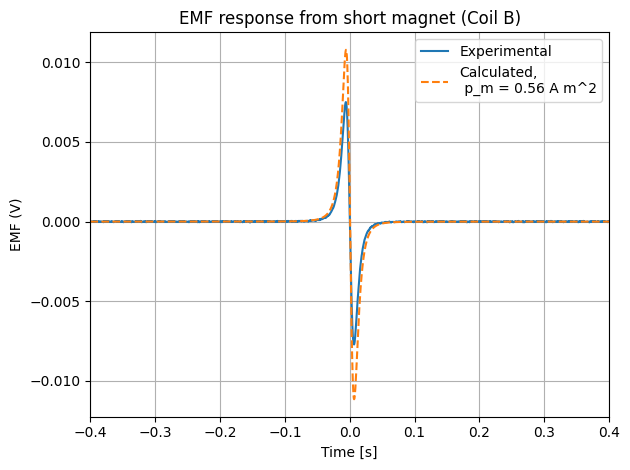

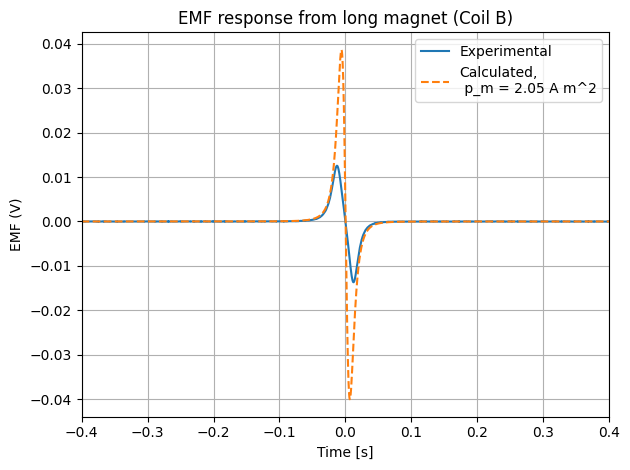

In [57]:
# Calcs

ro = 0.0442  # coil diameter
N = 20  # number of turns
# short

t = np.linspace(np.min(t_short), np.max(t_short), 2000)
z = 0.5 * 9.41 * t ** 2 + 3.54 * t - 0.0019
v = 9.41 * t + 3.54
eps = (-3 / 2) * N * MU0 * dipole_m_short * ro ** 2 * ((z) / (ro ** 2 + z ** 2) ** (5 / 2)) * v

# plot EMF coil B calc and exp

fig, ax = plt.subplots(1, 1)
ax.set_title("EMF response from short magnet (Coil B)")
ax.plot(t_short, VB_short, "-", label="Experimental")
ax.plot(t, eps, "--", label=f"Calculated,\n p_m = {dipole_m_short:.2f} A m^2")
ax.set_xlabel("Time [s]")
ax.set_ylabel("EMF (V)")
ax.set_xlim(-0.4, 0.4)
ax.legend(loc="best")
ax.grid(True)
plt.tight_layout()
# plt.savefig("figures/short_coilB.png")
plt.show()

# long

t = np.linspace(np.min(t_long), np.max(t_long), 2000)
z = 0.5 * 9.48 * t ** 2 + 3.46 * t - 0.0015
v = 9.48 * t + 3.46
eps = (-3 / 2) * N * MU0 * dipole_m_long * ro ** 2 * (z / (ro ** 2 + z ** 2) ** (5 / 2)) * v

fig, ax = plt.subplots(1, 1)
ax.set_title("EMF response from long magnet (Coil B)")
ax.plot(t_long, VB_long, "-", label="Experimental")
ax.plot(t, eps, "--", label=f"Calculated,\n p_m = {dipole_m_long:.2f} A m^2")
ax.set_xlabel("Time [s]")
ax.set_ylabel("EMF (V)")
ax.set_xlim(-0.4, 0.4)
ax.legend(loc="best")
ax.grid(True)
plt.tight_layout()
plt.savefig("figures/long_coilB.png")
plt.show()


### Consistency Checks

In [ ]:
# Consistency checks
print(em.consistency_check(g, mass))

### Sample Calculations

In [ ]:
%%tex sci_not

#TeX calculations
y1_exp = N1_index[1] * wl / (unp.cos(a) + 1)

### Raw data tables to LaTeX


In [ ]:
selected_columns = ['Notch', 'l [mm]', 'T [sec]']
latex_code = df[selected_columns].to_latex(
    index=False,
    float_format="%.4f",  # Restricts decimal overflow automatically
    caption="Bar",
)

print(latex_code)